# 2. Single Dispersive Interface: Wavelength-Dependent Optical Constants

## Physical Motivation & Learning Objectives
Real optoelectronic materials exhibit **chromatic dispersion** where the complex refractive index $\tilde{n}(\lambda) = n(\lambda) + i \kappa(\lambda)$ varies with wavelength. In this tutorial:
1. We simulate a planar interface between air and crystalline silicon using tabulated optical constants (`materials.Si_c`).
2. We evaluate how interband transitions in the ultraviolet affect reflectance and absorbance.
3. We parallelize wavelength sweeps using Python's `concurrent.futures`.



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



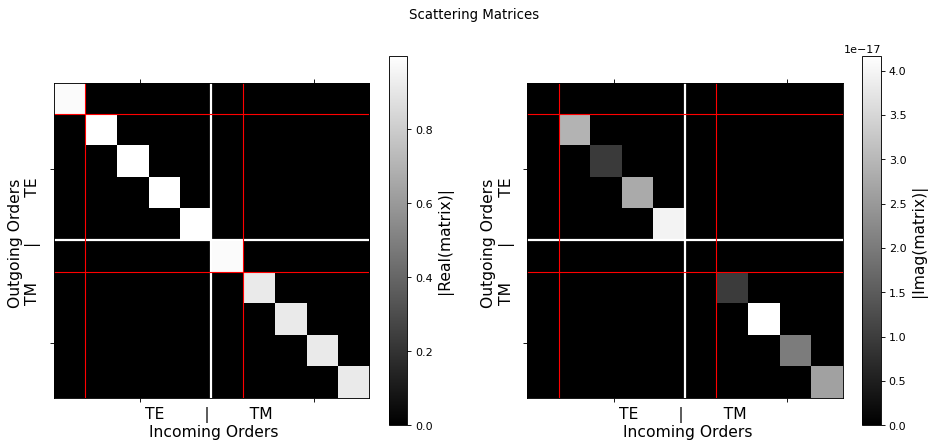

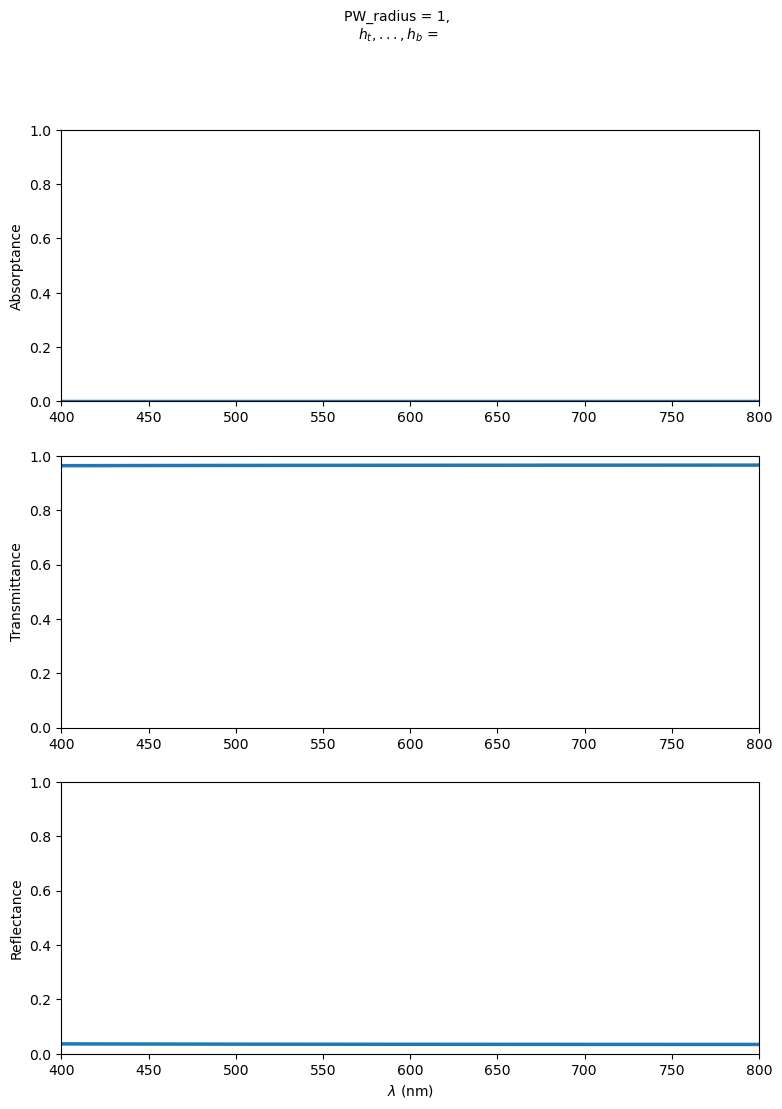

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack

wl_1 = 400.0
wl_2 = 800.0
no_wl_1 = 21
wavelengths = np.linspace(wl_1, wl_2, no_wl_1)
light_list = [objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0) for wl in wavelengths]

period = 300.0
superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.SiO2)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    stk = Stack((sim_sub, sim_sup))
    stk.calc_scat(pol='TM')
    return stk

stacks_list = [simulate_stack(l) for l in light_list]

T_net = stacks_list[-1].T_net
nu_prop = stacks_list[-1].layers[0].num_prop_pw_per_pol
fig_mat = plotting.vis_scat_mats(T_net, nu_prop_PWs=nu_prop)
plt.show()

figs_tra = plotting.t_r_a_plots(stacks_list)
plt.show()


## Layer Definitions & Material Dispersion Setup

We sweep across the near-UV to near-infrared spectrum ($\lambda \in [300, 1100]$ nm). Silicon's refractive index is automatically interpolated from experimental optical constants.


## Dispersive Reflection and Absorption Spectra


## Physical Interpretation
- Near $\lambda \approx 370$ nm, silicon exhibits peak absorption and high refractive index ($n > 5$), causing reflectance to exceed $50\%$.
- As wavelength extends beyond the silicon band edge ($\lambda > 1100$ nm), the extinction coefficient $\kappa \to 0$, rendering silicon transparent.
